In [95]:
from src.InverseHeatModel import InverseHeatModel
from src.print_utils import print_kv, print_section

import torch
import h5py
import matplotlib.pyplot as plt

import numpy as np
import torch
import torch.nn as nn

plt.style.use("styles/plots.mplstyle")

In [96]:
def make_windows(g: torch.Tensor, f: torch.Tensor, W: int) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Info:
        Divide each sample (n_timesteps) into windows of size W. The windows do not overlap.

        The last n_timesteps % W observables are discarded if n_timesteps
        is not divisible by W.
        
    Args:
        g: (n_samples, n_timesteps)
        f: (n_samples, n_timesteps)
        W: windows length in samples
 
    Returns:
        g_wins: (n_samples, n_windows, W)
        f_wins: (n_samples, n_windows, W)
 
    """
    n_samples, T = g.shape
    n_windows = T // W
 
    g_wins = g[:, : n_windows * W].reshape(n_samples, n_windows, W)
    f_wins = f[:, : n_windows * W].reshape(n_samples, n_windows, W)
 
    return g_wins, f_wins


In [97]:
def train(
    model,
    g_tr_wins:  torch.Tensor,
    f_tr_wins:  torch.Tensor,
    g_va_wins:  torch.Tensor,
    f_va_wins:  torch.Tensor,
    n_epochs:           int   = 2000,
    lr:                 float = 1e-3,
    weight_decay:       float = 0.0,
    checkpoint_path:    str   = "assets/tikhonov_learned/best_tikhonov.pt",
    log_every:          int   = 100,
    save_every:         int   = 100,   
) -> dict:
    """
    Info:
        Training loop with non overlapping windows.
 
    Args:
        model:   InverseHeatModel
        g_tr_wins:  (n_samples, n_windows, W)
        f_tr_wins:  (n_samples, n_windows, W)
        g_va_wins:  (n_samples, n_windows, W)
        f_va_wins:  (n_samples, n_windows, W)
        
    Return:
        hisotory:   dict{
            "train_loss": list, 
            "val_loss"  : list, 
            "lr"        : list
            }
    """
    
    _, _, W = g_tr_wins.shape
    
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=2000, T_mult=2, eta_min=1e-6
    )
    loss_fn = nn.MSELoss()
    
    history     = {"train_loss": [], "val_loss": [], "lr": []}
    best_val    = float("inf")
        
    print_section("Training")
    for epoch in range(1, n_epochs + 1):
 
        # Training step                                                       
        model.train()
        optimizer.zero_grad()
 
        loss_train = _windowed_loss(model, g_tr_wins, f_tr_wins, loss_fn)
 
        loss_train.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
 
        # Validation step                                                     
        model.eval()
        with torch.no_grad():
            loss_val = _windowed_loss(model, g_va_wins, f_va_wins, loss_fn)
 
        train_l = loss_train.item()
        val_l   = loss_val.item()
 
        scheduler.step(val_l)
        current_lr = optimizer.param_groups[0]["lr"]
 
        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)
        history["lr"].append(current_lr)

        # Save checkpoint if the current validation loss is less then the previous one.
        # In this case update the min validation loss
        if epoch % save_every == 0:
            if val_l < best_val:
                best_val = val_l
                torch.save(
                    {
                        "epoch":           epoch,
                        "model_state":     model.state_dict(),
                        "optimizer_state": optimizer.state_dict(),
                        "val_loss":        best_val,
                        "W":               W,
                    },
                    checkpoint_path,
                )
 
        if epoch % log_every == 0 or epoch == 1:
            print(
                f"Epoch {epoch:5d}/{n_epochs} | "
                f"train MSE: {train_l:.4e} | "
                f"val MSE: {val_l:.4e} | "
                f"lr: {current_lr:.2e}"
            )
 
    print(f"\nBest val MSE: {best_val:.4e} -> {checkpoint_path}")
    return history
 
 
def _windowed_loss(model: InverseHeatModel, g_wins: torch.Tensor, f_wins: torch.Tensor, loss_fn) -> float:
    """
    Info:
        Compute the mean loss over all the windows for each sequence of measurements
        For each sequence of windows iterate over the windows and reconstruct the current sample
        passing the previous windows g as g_prev.
    
        The loss is mean over all the samples and all the windows, excluding the first windows for every sample
        where g_prev = 0 by definition (The system is assumed to be in Thermal equilibrium with the ambient at the start, e.g. T=0 for all x).
        
    Args:
        g_wins: (n_samples, n_windows, W)
        f_wins: (n_samples, n_windows, W)
    
    Return:
        total_loss: float
    """
    n_samples, n_windows, W = g_wins.shape
    device = g_wins.device
 
    preds = [] 
 
    for i_win in range(n_windows):
        g_cur = g_wins[:, i_win, :]             # (n_samples, W)
 
        if i_win == 0:
            # First windows: g_prev = zero
            g_prev = torch.zeros_like(g_cur)
        else:
            g_prev = g_wins[:, i_win - 1, :]    # (n_samples, W)
 
        f_pred = model(g_cur, g_prev)           # (n_samples, W)
        preds.append(f_pred)

    preds = torch.stack(preds, dim=1)           # (n_samples, n_windows, W)
    
    return loss_fn(preds, f_wins)

# Dataset Loading

In [98]:
DATASET_CODE    = "w50/"
H5_PATH         =  f"dataset/{DATASET_CODE}dataset.h5"
M               = 1                   
W               = 333                 
VAL_FRACTION    = 0.1
SEED            = 42

In [99]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print_kv("Device", f"{device}")

Device                                                            cuda


In [100]:
# --- Load simulation parameters --------
L, Tf, nt, D, h_param, l, _, r, _ = np.loadtxt(
    f"dataset/{DATASET_CODE}simulation_info.csv", delimiter=";", usecols=1
)

nt = int(nt)            # Number of time samples
dt = Tf / nt            # Sampling time interval

nk  = int(2 * W - 1)    # Number of discrete frequencies in a windows
n_windows = nt // W     # Number of windows
tau = int(L*L/D/dt)

if W > tau:
    raise Warning("W bigger then tau")

print_kv("L         [m]"        , f"{L}")
print_kv("Tf        [sec]"      , f"{Tf}")
print_kv("D"                    , f"{D}")
print_kv("Tau       [sample]"   , f"{tau}")
print_kv("W         [sample]"   , f"{W}")
print_kv("n_windows"            , f"{n_windows}")
print_kv("nt"                   , f"{nt}")
print_kv("dt        [sec]"      , f"{dt}")
print_kv("nk"                   , f"{nk}")

L         [m]                                                      1.0
Tf        [sec]                                                   30.0
D                                                                  1.0
Tau       [sample]                                                 333
W         [sample]                                                 333
n_windows                                                           30
nt                                                               10000
dt        [sec]                                                  0.003
nk                                                                 665


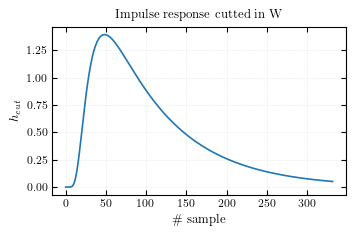

In [101]:
# --- Load impulse response --------------
h       = np.loadtxt( f"dataset/{DATASET_CODE}impulse_response.csv", delimiter=";")
h_cut   = h[:W]
H       = np.fft.rfft(h_cut, nk).astype(np.complex64)
freqs   = np.fft.rfftfreq(nk, d=dt)
omegas  = freqs * 2 * np.pi

# --- Cut the impulse response into the window
# The impulse response should be negligible before the end of the window
plt.plot(h_cut)
plt.xlabel("\# sample")
plt.ylabel(r"$h_{cut}$")
plt.title("Impulse response cutted in W")
plt.grid()
plt.show()

In [102]:
# ---- Load dataset ----------------------

with h5py.File(H5_PATH, "r") as hf:
    data = hf["dataset"][:]              # (N, 2, nt)

f_all = data[:, 0, :].astype(np.float32)
g_all = data[:, 1, :].astype(np.float32)

# --- Validation and trainign set declaration --------

N = len(f_all)

rng       = np.random.default_rng(SEED)
idx       = rng.permutation(N)
n_val     = max(1, int(VAL_FRACTION * N))
idx_val   = idx[:n_val]
idx_train = idx[n_val:]

g_train = torch.from_numpy(g_all[idx_train]).to(device)
f_train = torch.from_numpy(f_all[idx_train]).to(device)
g_val   = torch.from_numpy(g_all[idx_val]).to(device)
f_val   = torch.from_numpy(f_all[idx_val]).to(device)

In [103]:
# Divide the dataset into windows. This is performed only once here.
# Shape: (n_samples, n_timesteps) -> (n_samples, n_windows, W)
g_tr_wins, f_tr_wins = make_windows(g_train ,f_train   ,W)
g_va_wins, f_va_wins = make_windows(g_val   ,f_val     ,W)

n_samples_tr    ,n_windows_tr  ,_ = g_tr_wins.shape
n_samples_val   ,n_windows_val ,_ = g_va_wins.shape

print_section("Training Dataset")

print_kv("n_samples"                , f"{n_samples_tr}")
print_kv("n_windows per sample"     , f"{n_windows_tr}")
print_kv("tot windows"              , f"{n_samples_tr*n_windows_tr}")

print_section("validation Dataset")

print_kv("n_samples"                  , f"{n_samples_val}")
print_kv("n_windows per sample"       , f"{n_windows_val}")
print_kv("tot windows"                , f"{n_samples_val*n_windows_val}")


---------------------------Training Dataset---------------------------

n_samples                                                          270
n_windows per sample                                                30
tot windows                                                       8100

--------------------------validation Dataset--------------------------

n_samples                                                           30
n_windows per sample                                                30
tot windows                                                        900


# Model Initialization

In [104]:
model = InverseHeatModel(H=H, nt=W, dt=dt, M=M).to(device)

# Load pretrained model
LOAD_LOCATION = "assets/tikhonov_learned/w50/best_tikhonov.pt"
PRELOAD_MODEL = False

if LOAD_LOCATION != None and PRELOAD_MODEL == True:
    ckpt = torch.load(LOAD_LOCATION, map_location="cpu")
    model.load_state_dict(ckpt["model_state"])
    model.to(device)
    print_kv("Model preloaded", LOAD_LOCATION)

n_params = sum(p.numel() for p in model.parameters())

print_kv("Parameters number", f"{n_params}")
print_kv("Phi", f"{W}")
print_kv("log_R", f"{W}")
print_kv(f"Sigma (M = {model.sigma.M})", f"{(model.sigma.M*2 + 1) * W}")

Parameters number                                                 1665
Phi                                                                333
log_R                                                              333
Sigma (M = 1)                                                      999


In [105]:
@torch.no_grad()
def predict(model, g: torch.Tensor, W: int) -> torch.Tensor:
    """
    Info:
        Reconstruct an entire sample f of length n_timesteps from g by first cutting it into windows of
        size W and then reconstruct each windows sequentially.
 
    Args:
        g: (n_timesteps,) or (n_samples, n_timesteps)
        W: window length, it must be the same used during training
 
    Returns:
        f_pred: same shape as g
    """
    squeeze = g.dim() == 1
    if squeeze:
        g = g.unsqueeze(0)   # (1, T)
 
    n_samples, T    = g.shape
    n_windows       = T // W
    g_trim          = g[:, : n_windows * W]

    g_wins          = g_trim.reshape(n_samples, n_windows, W)
    preds           = []
 
    for i_win in range(n_windows):
        g_cur  = g_wins[:, i_win, :]
        g_prev = g_wins[:, i_win - 1, :] if i_win > 0 else torch.zeros_like(g_cur)
        preds.append(model(g_cur, g_prev))
 
    f_pred = torch.cat(preds, dim=-1)   # (n_samples, n_windows * W)
 
    return f_pred.squeeze(0) if squeeze else f_pred

In [106]:
def predictions_plot(
    g_val: torch.Tensor, 
    f_val: torch.Tensor,
    W: int, 
    n_plots: int = 6,
    ncols = 3,
    max_window = 7,
    min_window = 0,
    ):
    
    max_index = max_window*W
    min_index = min_window*W

    nrows = int(np.ceil(n_plots / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14, 3 * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=False
    )

    axes = np.array(axes).reshape(-1)

    for index in range(n_plots):

        g_test = g_val[index][:max_index]
        f_test = f_val[index][:max_index]
        f_pred = predict(model,g_test,W)

        ax = axes[index]
        
        ax.plot(g_test.cpu().numpy(), label=r"$g$",        c="k")
        ax.plot(f_test.cpu().numpy(), label=r"$f_{true}$", c="b", lw=4,  alpha =0.5)
        ax.plot(f_pred.cpu().numpy(), label=r"$f_{rec}$",  c="r")
        
        # Plot windows separation and windows number
        for j in range(n_windows + 1):
            ax.axvline(W*j, c="k", ls="-.", alpha =0.8, lw=1)
            
            if W*j >= min_index and W*j < max_index:
                ax.text(W*(j+0.5),2,j)
            
        ax.set_xlim([min_index, max_index])
        ax.set_ylim([-3, 3])
        ax.set_title(f"Sample {index}")
        ax.grid()
        
    # Hide subplot not used
    for k in range(n_plots, len(axes)):
        axes[k].axis("off")

    # Only one legend
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=3
    )

    fig.supxlabel("time sample")
    fig.supylabel("signal amplitude")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    plt.show()

# Training

In [107]:
history = None
DO_TRAINING = True

## First training

Only train $R$ and $\phi$ on the first window where g_prev = 0 and the system is LTI


-------------------------------Training-------------------------------

Epoch     1/20000 | train MSE: 6.2126e+02 | val MSE: 6.0899e+02 | lr: 7.88e-04
Epoch  1000/20000 | train MSE: 2.8574e+01 | val MSE: 2.7880e+01 | lr: 1.00e-03
Epoch  2000/20000 | train MSE: 5.4626e-02 | val MSE: 7.0267e-02 | lr: 1.00e-03
Epoch  3000/20000 | train MSE: 5.2612e-02 | val MSE: 6.8708e-02 | lr: 1.00e-03
Epoch  4000/20000 | train MSE: 5.2035e-02 | val MSE: 6.7974e-02 | lr: 1.00e-03
Epoch  5000/20000 | train MSE: 5.1196e-02 | val MSE: 6.6924e-02 | lr: 1.00e-03
Epoch  6000/20000 | train MSE: 4.9891e-02 | val MSE: 6.5224e-02 | lr: 1.00e-03
Epoch  7000/20000 | train MSE: 4.8108e-02 | val MSE: 6.2860e-02 | lr: 1.00e-03
Epoch  8000/20000 | train MSE: 4.5790e-02 | val MSE: 5.9816e-02 | lr: 1.00e-03
Epoch  9000/20000 | train MSE: 4.3143e-02 | val MSE: 5.6360e-02 | lr: 1.00e-03
Epoch 10000/20000 | train MSE: 4.0558e-02 | val MSE: 5.3000e-02 | lr: 1.00e-03
Epoch 11000/20000 | train MSE: 3.8370e-02 | val MSE: 5.014

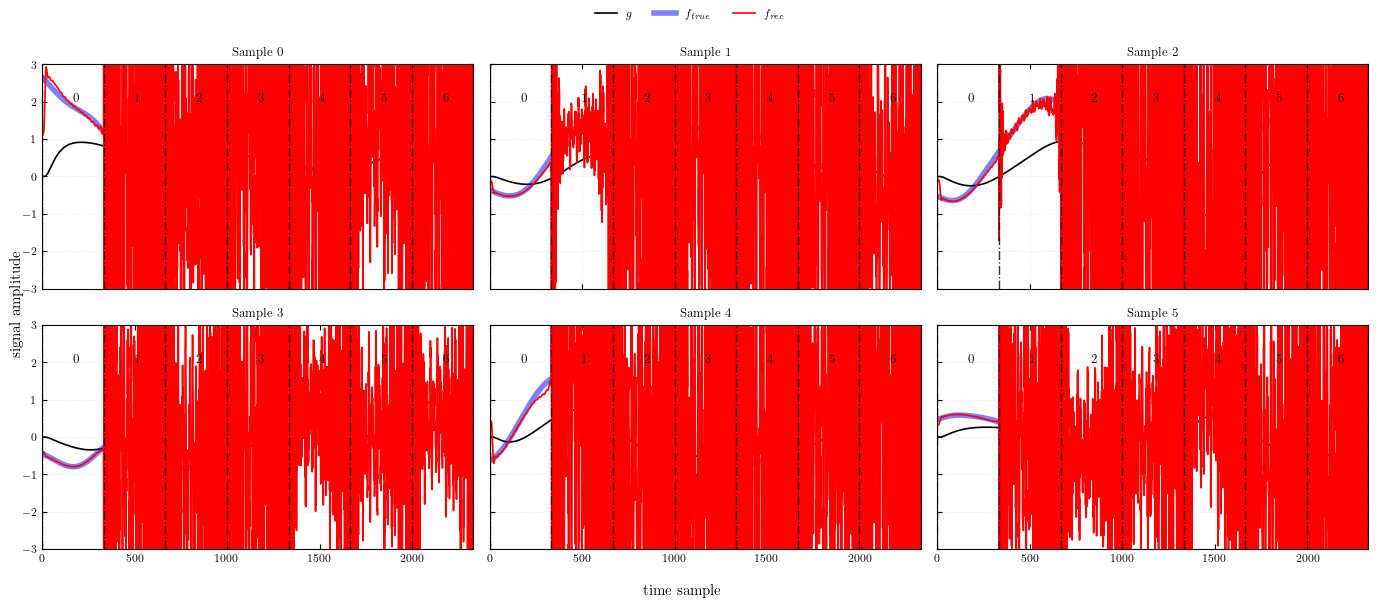

In [ ]:
if DO_TRAINING:
    
    model.freeze_all()
    model.unfreeze_phi()
    model.unfreeze_R()
    
    history = train(
        model        = model,
        g_tr_wins    = g_tr_wins[:,[0],:],
        f_tr_wins    = f_tr_wins[:,[0],:],
        g_va_wins    = g_va_wins[:,[0],:],
        f_va_wins    = f_va_wins[:,[0],:],
        n_epochs     = 20000,
        checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
        log_every    = 1000
    )
    
predictions_plot(g_val, f_val, W = W)

## Second training

Only train the real diagonal and the first off diagonal of $\Sigma$ 


-------------------------------Training-------------------------------

Epoch     1/1000 | train MSE: 3.0645e+03 | val MSE: 3.0119e+03 | lr: 8.50e-04
Epoch   100/1000 | train MSE: 1.9975e+03 | val MSE: 1.9890e+03 | lr: 1.07e-06
Epoch   200/1000 | train MSE: 1.9963e+03 | val MSE: 1.9878e+03 | lr: 1.09e-06
Epoch   300/1000 | train MSE: 1.9950e+03 | val MSE: 1.9866e+03 | lr: 1.11e-06
Epoch   400/1000 | train MSE: 1.9938e+03 | val MSE: 1.9854e+03 | lr: 1.13e-06
Epoch   500/1000 | train MSE: 1.9925e+03 | val MSE: 1.9841e+03 | lr: 1.16e-06
Epoch   600/1000 | train MSE: 1.9912e+03 | val MSE: 1.9828e+03 | lr: 1.18e-06
Epoch   700/1000 | train MSE: 1.9898e+03 | val MSE: 1.9815e+03 | lr: 1.21e-06
Epoch   800/1000 | train MSE: 1.9884e+03 | val MSE: 1.9801e+03 | lr: 1.24e-06
Epoch   900/1000 | train MSE: 1.9870e+03 | val MSE: 1.9787e+03 | lr: 1.28e-06
Epoch  1000/1000 | train MSE: 1.9855e+03 | val MSE: 1.9773e+03 | lr: 1.32e-06

Best val MSE: 1.9773e+03 -> assets/tikhonov_learned/w50/best_tikhono

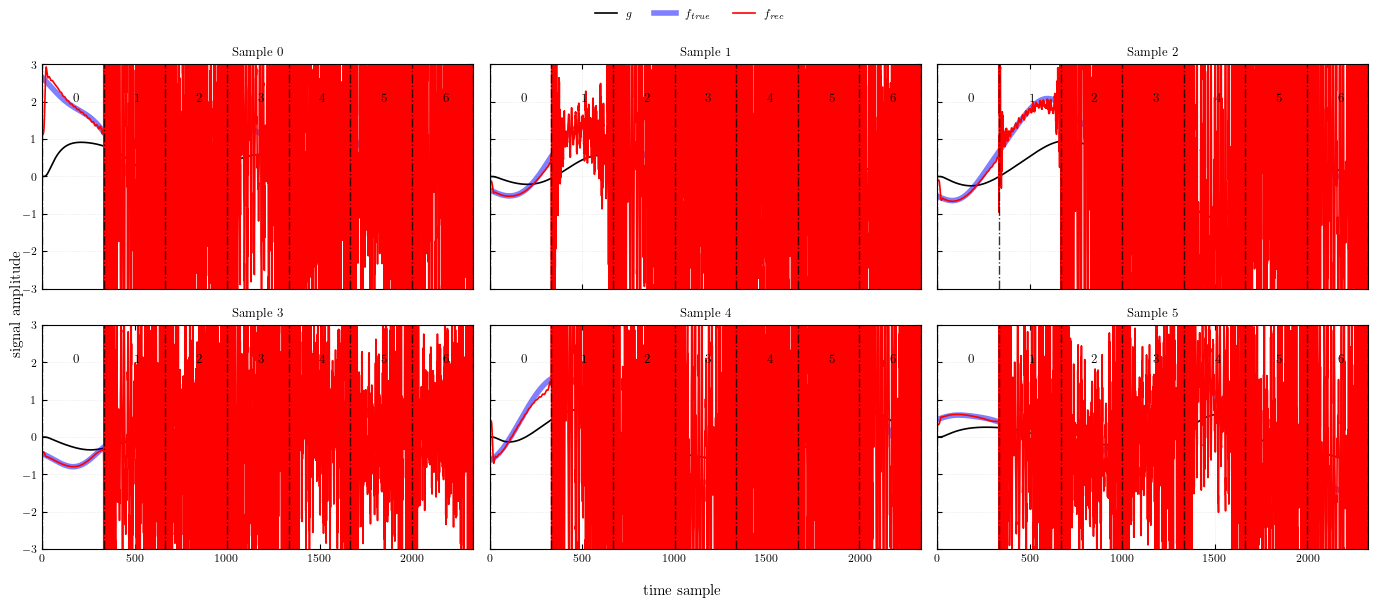

In [109]:
if DO_TRAINING:
    
    model.freeze_all()
    model.unfreeze_sigma()
    
    history = train(
        model        = model,
        g_tr_wins    = g_tr_wins,
        f_tr_wins    = f_tr_wins,
        g_va_wins    = g_va_wins,
        f_va_wins    = f_va_wins,
        n_epochs     = 1000,
        checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt"
    )

predictions_plot(g_val, f_val, W = W)

## Third training

Increase M up to 5 and train the remaining off diagonals of $\Sigma$ 

In [ ]:
if DO_TRAINING:
    
    model = model.sigma.increase_bandwidth(model,5)
    
    history = train(
        model        = model,
        g_tr_wins    = g_tr_wins,
        f_tr_wins    = f_tr_wins,
        g_va_wins    = g_va_wins,
        f_va_wins    = f_va_wins,
        n_epochs     = 1000,
        checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt"
    )
    
predictions_plot(g_val, f_val, W = W)


-------------------------------Training-------------------------------

Epoch     1/1000 | train MSE: 1.9727e+03 | val MSE: 1.9273e+03 | lr: 4.25e-06
Epoch   100/1000 | train MSE: 1.9153e+03 | val MSE: 1.9087e+03 | lr: 6.13e-06
Epoch   200/1000 | train MSE: 1.8867e+03 | val MSE: 1.8806e+03 | lr: 9.76e-06
Epoch   300/1000 | train MSE: 1.8393e+03 | val MSE: 1.8338e+03 | lr: 1.79e-05
Epoch   400/1000 | train MSE: 1.7461e+03 | val MSE: 1.7416e+03 | lr: 4.16e-05


In [ ]:
def plot_diagnostics(model, omegas: np.ndarray):
    
    fig, axes = plt.subplots(3, 1, figsize=(3.2, 3.6), sharex=True)

    ax1, ax2, ax3 = axes
    
    # Phi Plot
    ax1.plot(omegas, np.degrees(model.get_phi()), color="steelblue", lw=1.5)
    ax1.axhline(0, color="k", lw=0.2, ls="--")
    ax1.set_ylabel(r"$\phi_\theta$")
    ax1.set_title(r"Learned model $W_\theta$")
    ax1.grid(True, alpha=0.3)
    
    # R plot
    ax2.semilogy(omegas, model.get_R(), color="darkorange", lw=1)
    ax2.set_ylabel(r"$R_\theta$")
    ax2.set_title("")
    ax2.grid(True, alpha=0.3)

    # W plot
    ax3.semilogy(omegas, model.get_W_magnitude(), color="r", lw=1, label=r"Learned $|W_\theta|$")
        
    ax3.set_ylabel(r"$|W|$")
    ax3.set_xlabel(r"$\omega$")
    ax3.set_title("")
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    plt.show()
    
def plot_history(history: dict):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots()
    
    ax.semilogy(epochs, history["train_loss"], label="Train MSE")
    ax.semilogy(epochs, history["val_loss"],   label="Val MSE", ls="--")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_title("Loss curve")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

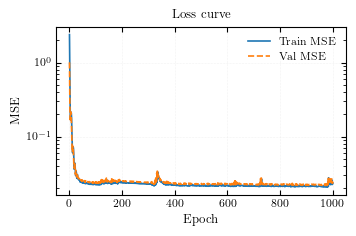

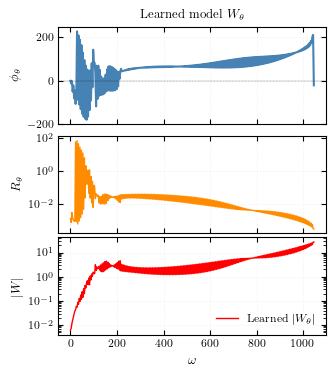

In [ ]:
if history is not None:
    plot_history(history=history)

plot_diagnostics(model=model, omegas=omegas)